# Homework 8 — Gradient Boosting and K-Means Clustering

## Due: 11/3

# Part A: Gradient Boosting

## Conceptual Question
### **Q1** In gradient boosting for squared-error regression, why is a new tree trained on the *current residuals* instead of the original target values? What does a positive residual tell us?

### Answer
Each tree learns to correct the errors of the current combination of learners. For squared error regression, the residual is the negative gradient of the loss:

$$
r_i = y_i - \hat{y_i}
$$

So, fitting it gives a direction that reduces error. Training on the original targets wouldn't address the current combination's remaining mistakes / errors.

A positive residual means the model undepredicted: the true value is higher than the prediction.

### **Q2** Explain why a very deep tree used as the weak learner in boosting is risky.

### Answer
A very deep tree can overfit - fit the noise and outliers in the residuals. It can also make overly specific corrections that generalize poorly. Shallow trees and a small learning rate should be used as they help control this risk of overfitting.

### **Q3** Give two differences between random forest and gradient boosting (not including "one is bagging, the other is boosting").

### Answer
- Training: Random forest trees can be trained independently and in parallel. Gradient boosting trees need to be trained sequentially, with each using the current combination's errors.
- Combining Predictions: A random forest averages its trees' predictions to make a prediction. Gradient boosting adds scaled tree predictions to an initial prediction, with the learning rate controlling each tree's contribution.

## Calculation Question

### **Q4** A machine's wear $y$ is measured at five load levels $x$:

| $x$ | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| $y$ | 2 | 1 | 6 | 12 | 14 |

Use gradient boosting with **MSE loss** and **decision stumps** (one split, leaf value = mean of the residuals in the leaf). Choose the split by minimizing the **weighted MSE** of the residuals, as in lecture, with candidate thresholds $x=1.5,\,2.5,\,3.5,\,4.5$. Use learning rate $\eta=0.5$.

#### **(a)** Compute the initial prediction $F_0(x)$ and the residual sum of squares (RSS).

 ### Answer

The initial prediction is the mean of the targets:

$$
F_0(x) = \hat{y} = \frac{2 + 1 + 6 + 12 + 14}{5} = 7
$$

The residuals are:

$$
r_i = y_i - F_0(x_i)
$$

Which yields: 

$$
r = (-5, -6. -1, 5, 7)
$$ 

Thus:

$$
RSS = \sum_{i=1}^{n} (y_i - \hat{y_i})^2
$$

$$
RSS_0 = (-5)^2 + (-6)^2 + (-1)^2 + (5)^2 + (7)^2 = 136
$$

### **(b)** Fill in the table of candidate splits for **Tree 1** (residuals from part (a)). Which split is chosen, and what are the two leaf values?

$$
MSE_{leaf} = \frac{1}{n_{leaf}} \sum_{i}^{n} (r_i - \bar{r_{leaf}})^2
$$

$$
MSE_{weighted} = \frac{n_L}{5} MSE_L  + \frac{n_R}{5} MSE_R
$$

| Split | Left residuals | Right residuals | Left MSE | Right MSE | Weighted MSE |
|---|---|---|---|---|---|
| 1.5 | -5 | -6, -1, 5, 7 | 0 | 26.1875 | 20.95 |
| 2.5 | -5, -6 | -1, 5, 7 | 0.25 | 11.56 | 7.03 |
| 3.5 | -5, -6, -1 | 5, 7 | 4.67 | 1 | 3.2 |
| 4.5 | -5, -6, -1, 5 | 7 | 18.6875 | 0 | 14.95 |

### Answer
$x = 3.5$ is has the lowest weighted MSE and therefore is chosen. The leaf values are:

$$
\bar{r_L} = \frac{-5 -6 -1}{3} = -4
$$

$$
\bar{r_R} = \frac{5+7}{2} = 6
$$

### **(c)** Write the updated prediction $F_1(x)$ for all five points and compute the new RSS.

### Answer

Learning rate of 0.5.

$$
F_1(x) = F_0(x) + 0.5 h_1(x) = \begin{cases}
7 + 0.5(-4) = 5, & x \le 3.5, \\
7 + 0.5(6) = 10, & x > 3.5
\end{cases}
$$

| x | 1 | 2 | 3 | 4 | 5 |
| :--- | ---: | ---: | ---: | ---: | ---: |
| **$F_1(x)$** | 5 | 5 | 5 | 10 | 10 |
| **New residual** | -3 | -4 | 1 | 2 | 4 |

$$
RSS_1 = 9 + 16 + 1 + 4 + 16 = 46
$$

### **(d)** If the learning rate were $1.0$ instead, what would the five updated predictions be? 

### Answer

$$
(3, 3, 3, 13, 13)
$$

$$
RSS_1 = 1 + 4 + 9 + 1 + 1 = 16
$$

### **(e)** Although a larger learning rate produces a lower training RSS in this example, why might we still prefer a smaller learning rate when training a Gradient Boosting model with many trees?

### Answer

A smaller learning rate makes each tree’s correction more gradual, reducing the risk of fitting noise and overfitting across many trees. It typically requires more trees, but can improve performance on unseen data.

## Python Coding Question

Use a small synthetic regression dataset. Keep the train/test split fixed for a fair comparison.

### **Q5** Fill in the code to train a `GradientBoostingRegressor` with `n_estimators=30`, `max_depth=2`, and `learning_rate=0.1`. Calculate train and test MSE.

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
X = np.linspace(0, 6, 120).reshape(-1, 1)
y = np.sin(X[:, 0]) + 0.15 * rng.normal(size=len(X))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

# construct, fit, predict, and print both train and test MSE values
model = GradientBoostingRegressor(n_estimators=30, max_depth=2, learning_rate=0.1)
model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
print(f"Train MSE: {train_mse:.4f}")
print(f"Test MSE: {test_mse:.4f}")

Train MSE: 0.0155
Test MSE: 0.0235


### **Q6** Repeat for learning rates `[0.01, 0.1, 0.5]`, keeping all other settings unchanged. Print the test MSE for each.

In [28]:
learning_rates = [0.01, 0.1, 0.5]
for lr in learning_rates:
    model = GradientBoostingRegressor(n_estimators=30, max_depth=2, learning_rate=lr)
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    print(f"Train MSE (lr={lr}): {train_mse:.4f}")
    print(f"Test MSE (lr={lr}): {test_mse:.4f}")

Train MSE (lr=0.01): 0.3403
Test MSE (lr=0.01): 0.3268
Train MSE (lr=0.1): 0.0155
Test MSE (lr=0.1): 0.0235
Train MSE (lr=0.5): 0.0026
Test MSE (lr=0.5): 0.0267


### **Q7** Which learning rate performs best on this particular test split? Does this experiment prove it is always best? Explain.

### Answer

The learning rate of 0.1 performs best on this test split because it has the lowest test MSE of 0.0235. This doesn't prove it is always best. 

Performance depends on the dataset, train / test split, number of trees, and tree depth. Although 0.5 achieves lower training MSE, the higher test MSE suggests there's more overfitting.

# Part B: K-Means Clustering

## Conceptual Question
### **Q8** What do cluster labels represent in K-Means clustering? Do the numerical values of the labels (e.g., Cluster 0 and Cluster 1) have any inherent meaning?

### Answer

Cluster labels are which cluster each point belongs to. The numerical values are random / arbitrary ids with no order or inherent meaning. Swapping Cluster 0 and Cluster 1 would not change the clustering, for example.

### **Q9** Describe the two repeating steps in the K-Means algorithm. What is the centroid of a cluster?

### Answer

It repeats:
- The Assignment: Assigns each point to the nearest centroid
- The Update: Recomputes each centroid as the mean of all points assigned to that centroid.

A centroid is the mean of the points in a cluster in terms of coordinate (parameters).


## Calculation Question


Six sensors are represented by two features:

| Sensor | A | B | C | D | E | F |
|---|---|---|---|---|---|---|
| $(x_1,x_2)$ | (1,1) | (1,3) | (2,2) | (7,7) | (8,7) | (7,9) |

Set $K=2$ and initialize $\mu_1=(1,1)$, $\mu_2=(8,7)$. Use Euclidean distance; ties, if any, go to Cluster 1.

### **Q10** For each point, calculate its distance to both initial centroids and assign it to the nearest cluster. Show the calculations in a table.

### Answer

$$d(\mathbf{x},\boldsymbol{\mu})=\sqrt{(x_1-\mu_1)^2+(x_2-\mu_2)^2}.$$

| Sensor | $d(\mu_1)$ | $d(\mu_2)$ | Cluster |
|---|---:|---:|---|
| A | $ \sqrt{ (1 - 1)^2 + (1 - 1)^2} = 0 $ | $ \sqrt{ (1 - 8)^2 + (1 - 7)^2} = 9.2 $ | 1 |
| B | $ \sqrt{ (1 - 1)^2 + (3 - 1)^2} = 2 $ | $ \sqrt{ (1 - 8)^2 + (3 - 7)^2} = 8.06 $ | 1 |
| C | $ \sqrt{ (2 - 1)^2 + (2 - 1)^2} = 1.41 $ | $ \sqrt{ (2 - 8)^2 + (2 - 7)^2} = 7.81 $ | 1 |
| D | $ \sqrt{ (7 - 1)^2 + (7 - 1)^2} = 8.5 $ | $\sqrt{ (7 - 8)^2 + (7 - 7)^2} = 1 $ | 2 |
| E | $ \sqrt{ (8 - 1)^2 + (7 - 1)^2} = 9.2 $ | $\sqrt{ (8 - 8)^2 + (7 - 7)^2} = 0 $ | 2 |
| F | $ \sqrt{ (7 - 1)^2 + (9 - 1)^2} = 10 $ | $\sqrt{ (7 - 8)^2 + (9 - 7)^2} = 2.24 $ | 2 |


### **Q11** Recompute both centroids using the mean of the assigned points. Show the coordinates.

### Answer

The update centroids are:

$$
\mu_1 = (\frac{1+1+2}{3}, \frac{1+3+2}{3}) = (1.33, 2)
$$

$$
\mu_2 = (\frac{7+8+7}{3}, \frac{7+7+9}{3}) = (7.33, 7.67)
$$


### **Q12** Reassign all points using the new centroids. Did any assignments change? Based on your result, has the algorithm converged?

### Answer

| Sensor | d(μ₁) | d(μ₂) | Cluster |
|---|---:|---:|---|
| A | 1.0541 | 9.1954 | 1 |
| B | 1.0541 | 7.8669 | 1 |
| C | 0.6667 | 7.7817 | 1 |
| D | 7.5572 | 0.7454 | 2 |
| E | 8.3333 | 0.9428 | 2 |
| F | 9.0062 | 1.3744 | 2 |

No assignments changed. So the algorithm converged because another centroid update would give the same centroids, and subsequent assignments would remain unchanged.

### **Q13** Compute the within-cluster sum of squared distances (inertia) using the updated centroids and final assignments.

### Answer

$$J=\sum_{k=1}^{K}\sum_{\mathbf{x}_i\in C_k}\|\mathbf{x}_i-\boldsymbol{\mu}_k\|_2^2.$$

Using the updated centroids:

$$
J = \left(\frac{10}{9}+\frac{10}{9}+\frac{4}{9}\right)
+ \left(\frac{5}{9}+\frac{8}{9}+\frac{17}{9}\right)
= \frac{8}{3}+\frac{10}{3} = 6
$$

## Python Coding Question
Use the sensor data from calculation question.

**Q14** Fit `KMeans(n_clusters=2, init=initial_centroids, n_init=1, random_state=42)` and print labels, cluster centers, and inertia. 

**Q15** Make a scatter plot with points colored by cluster and mark both learned centroids with an `X` marker. Label axes and add a title.

**Q16** Fit K-Means for $K=1,2,3,4$ with `random_state=42` and `n_init=10`. Plot inertia against $K$. Explain why inertia never increases as $K$ increases for an optimal clustering, and why choosing the largest $K$ is not necessarily useful. 

In [29]:
from sklearn.cluster import KMeans

sensor_names = np.array(list("ABCDEF"))
X_sensor = np.array([[1, 1], [1, 3], [2, 2], [7, 7], [8, 7], [7, 9]], dtype=float)
initial_centroids = np.array([[1, 1], [8, 7]], dtype=float)

# fit model and print labels, centers, and inertia
km = KMeans(n_clusters=2, init=initial_centroids, n_init=1, random_state=42)
km.fit(X_sensor)
print("Labels:", km.labels_)
print("Centers:", km.cluster_centers_)
print("Inertia:", km.inertia_)

Labels: [0 0 0 1 1 1]
Centers: [[1.33333333 2.        ]
 [7.33333333 7.66666667]]
Inertia: 6.0


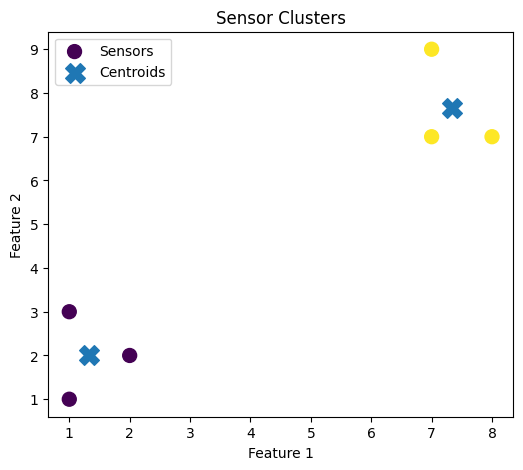

In [30]:
fig, ax = plt.subplots(figsize=(6, 5))
# plot the sensors and centroids
ax.scatter(X_sensor[:, 0], X_sensor[:, 1], c=km.labels_, s=100, label="Sensors")
ax.scatter(
    km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], marker="X", s=200, label="Centroids"
)
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_title("Sensor Clusters")
ax.legend()
plt.show()

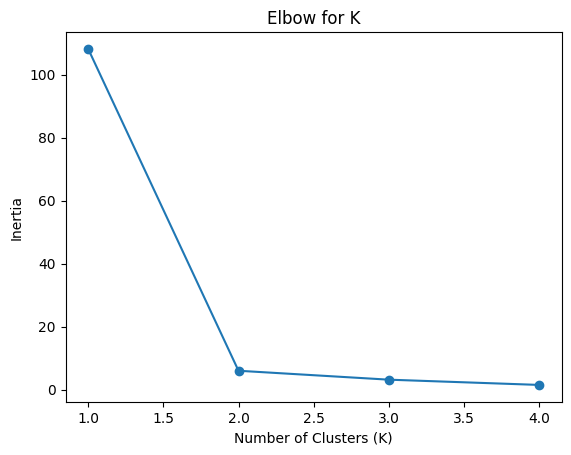

In [31]:
# compute and plot inertia for K = 1, 2, 3, 4
k_values = [1, 2, 3, 4]
inertias = [
    KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_sensor).inertia_ for k in k_values
]

plt.plot(k_values, inertias, "o-")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow for K")
plt.show()

### Q16 Answer


For an optimal clustering, inertia cannot increase as K increases because splitting a cluster makes its points be represented at least as well as before. 

But, choosing the largest K can create unnecessary clusters and fit noise. If every point has its own cluster, inertia is zero, but the clustering provides nothing useful. 

Here, K=2 is a reasonable choice because the largest decrease occurs from K=1 to K=2.